# 03. Extension: gene selection inside versus outside the evaluation loop

The baseline fits the ANOVA filter and the random-forest ranking on the training patients of each round. Here the same selection is instead fitted once on all 94 patients before resampling, so every held-out patient has already influenced which genes are used. Splits, models and seeds are identical to the baseline, so the two runs are paired round by round.

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from pipeline import CLASSES, evaluate, load_data

X, y = load_data()
inside = pd.read_csv('../results/baseline_scores.csv')

outside, _ = evaluate(X, y, n_rounds=100, seed=0, leak=True)
outside['workflow'] = outside['selection'] + '_' + outside['model']
outside.to_csv('../results/leak_scores.csv', index=False)

## Accuracy and balanced accuracy, inside versus outside

In [2]:
cols = ['accuracy', 'balanced_accuracy']
cmp = inside.groupby('workflow')[cols].mean().join(outside.groupby('workflow')[cols].mean(),
                                                    lsuffix='_inside', rsuffix='_outside')
cmp['accuracy_gap'] = cmp['accuracy_outside'] - cmp['accuracy_inside']
cmp['balanced_gap'] = cmp['balanced_accuracy_outside'] - cmp['balanced_accuracy_inside']
cmp = cmp.sort_values('accuracy_gap', ascending=False)
cmp.round(3)

,accuracy_inside,balanced_accuracy_inside,accuracy_outside,balanced_accuracy_outside,accuracy_gap,balanced_gap
workflow,,,,,,
s2_knn5_z,0.839,0.806,0.928,0.912,0.089,0.106
s2_knn5_iqr,0.825,0.791,0.904,0.899,0.079,0.108
s2_rf_mtry15,0.805,0.704,0.881,0.827,0.076,0.122
s2_rf_mtry5,0.791,0.656,0.859,0.719,0.068,0.063
s2_knn7_iqr,0.801,0.700,0.866,0.736,0.065,0.036
s2_knn3_z,0.852,0.847,0.917,0.907,0.065,0.060
s2_knn7_z,0.816,0.713,0.876,0.731,0.060,0.018
s2_knn3_iqr,0.840,0.844,0.899,0.903,0.059,0.060
s2_svm_C1_g0.001,0.694,0.416,0.752,0.451,0.058,0.035


In [3]:
def paired_p(w):
    a = inside.pivot(index='round', columns='workflow', values='accuracy')[w]
    b = outside.pivot(index='round', columns='workflow', values='accuracy')[w]
    return wilcoxon(b, a).pvalue

cmp['p_value'] = [paired_p(w) for w in cmp.index]
print(cmp.groupby(cmp.index.str[:2])[['accuracy_inside', 'accuracy_outside', 'accuracy_gap', 'balanced_gap']].mean().round(3))
print('workflows with significantly higher accuracy outside (p < 0.01):', int((cmp['p_value'] < 0.01).sum()), 'of', len(cmp))

          accuracy_inside  accuracy_outside  accuracy_gap  balanced_gap
workflow                                                               
s1                  0.753             0.767         0.014         0.033
s2                  0.809             0.873         0.063         0.063
workflows with significantly higher accuracy outside (p < 0.01): 23 of 24


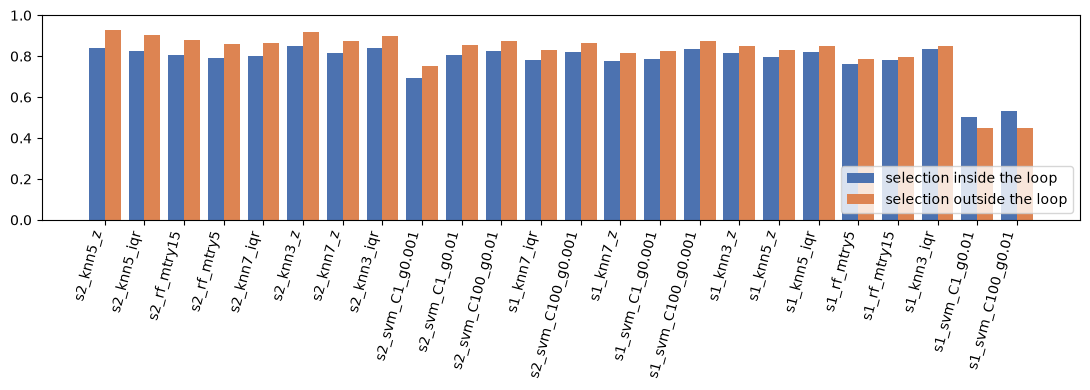

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(cmp))
ax.bar(x - 0.2, cmp['accuracy_inside'], 0.4, label='selection inside the loop', color='#4c72b0')
ax.bar(x + 0.2, cmp['accuracy_outside'], 0.4, label='selection outside the loop', color='#dd8452')
ax.set_xticks(x, cmp.index, rotation=75, ha='right')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/leakage_accuracy.png', dpi=120)
plt.show()

## Per-class recall, inside versus outside (all workflows averaged)

In [5]:
pd.DataFrame({'inside': inside[CLASSES].mean(), 'outside': outside[CLASSES].mean()}).round(3)

,inside,outside
NEG,0.826,0.866
BCR/ABL,0.792,0.822
ALL1/AF4,0.805,0.843
E2A/PBX1,0.393,0.476


## Notes

**What changed and why**

- Fitting the selection on all 94 patients before resampling raises accuracy for most workflows. The best workflow goes from 0.852 (inside) to 0.928 (outside, `s2_knn5_z` at 0.928 against 0.839 inside). The mean gain over all 24 workflows is +0.039 in accuracy and +0.048 in balanced accuracy; 23 of 24 workflows differ significantly (paired Wilcoxon, p < 0.01, optimistic because the rounds share patients).
- The gain comes from the held-out patients having influenced the choice of genes. The selected genes are those that already separate these labels well, including for the patients later used as the test set.
- The effect is concentrated in s2: +0.063 on average, against +0.014 for s1. Picking 30 genes out of thousands by importance leaves much more room to fit the labels than keeping every gene that passes the ANOVA test.
- The two exceptions are the two degenerate SVMs (`s1_svm_C1_g0.01`, `s1_svm_C100_g0.01`), which predict almost only NEG; their accuracy moves with the gene set rather than with any real signal and should not be read as a leakage effect.
- Per-class recall rises for every class, with the largest relative change for E2A/PBX1 (0.39 to 0.48 averaged over workflows). That class has only 5 patients, so it is the most exposed to this effect.

**What it means**

- A workflow evaluated with outside selection would be reported about 4 points better on average, and 7 to 9 points better for the best s2 workflows, than it would perform on new patients. The baseline numbers (selection inside) are the honest ones.
- The size of the inflation depends on how aggressive the selection is, which is why a comparison of selection strategies is only fair when selection is inside the loop.

**Limits**

- One seed and one split scheme (30% hold-out, 100 rounds). The sizes of the gaps are specific to this setup.
- The label-shuffle check in notebook 04 tests the same point from the other side: with no real signal, selection inside the loop should give about the always-NEG rate.